# Heat budget figure
(a) Coastal − offshore mixed-layer heat budget
(b) Coastal upwelling cooling vs stratification (1/MLD) and $W_{MLD}$
(c) Mean temperature and currents within the MLD

Standalone version of the combined figure in `SST_UV_paper.ipynb` (colour-blind-friendly variant).

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cmocean as cm
from scipy.io import loadmat

## Helper functions

In [2]:
def monthly_mean(data):
    return data.groupby('time.month').mean(dim='time')

def monthly_clim(ds):
    g = ds.groupby('time.month')
    return g.mean(), g.std()

def coastal_band_mask(ds, var='u10', target_width_km=111):
    """
    Create a coastal band mask with uniform cross-shore width in km.
    """
    da = ds[var]
    if 'time' in da.dims:
        da = da.mean(dim='time')

    valid2d = np.isfinite(da).values.astype(bool)
    lat_vals = ds['lat'].values
    lon_vals = ds['lon'].values
    dlon = np.abs(lon_vals[1] - lon_vals[0])  # grid spacing in degrees

    # Find coastline (easternmost valid cell per row)
    band = np.zeros_like(valid2d, dtype=bool)

    for j in range(valid2d.shape[0]):
        row = valid2d[j, :]
        ocean_cols = np.where(row)[0]
        if len(ocean_cols) == 0:
            continue

        # Coast = easternmost valid cell
        i_coast = ocean_cols[-1]

        # How many cells = target_width_km at this latitude?
        A = 6371.0  # km
        dx_km = A * np.cos(np.deg2rad(lat_vals[j])) * np.deg2rad(dlon)
        n_cells = int(np.round(target_width_km / dx_km))

        # Fill n_cells westward from coast
        i_start = max(i_coast - n_cells, 0)
        band[j, i_start:i_coast + 1] = True

    # Only keep cells that are actually ocean
    band = band & valid2d

    da_mask = xr.DataArray(band, dims=('lat', 'lon'),
                           coords={'lat': ds['lat'], 'lon': ds['lon']})
    return da_mask

def sym_lim(mean, factor=1.5):
    hw = abs(mean) * factor
    return (mean - hw, mean + hw)

## Data

In [3]:
# --- heat budget (coast / offshore boxes) ---
mat = loadmat("../data/Heat_budget.mat")

terms   = ['rate', 'forc', 'xadv', 'yadv', 'vadv', 'hmix', 'vmix', 'entr', 'temp']
regions = ['coast', 'off']

# !!! set the real start date of your run (guess below: Jan 1980) ---
time = pd.date_range("1980-01-01", periods=432, freq="MS")

data_vars = {}
for t in terms:
    cols = [np.asarray(mat[f"BUDGET_{r}_{t}"]).ravel() for r in regions]
    data_vars[t] = (("time", "region"), np.column_stack(cols).astype("float64"))

ds = xr.Dataset(data_vars, coords={"time": time, "region": regions})
ds

<xarray.Dataset> Size: 66kB
Dimensions:  (time: 432, region: 2)
Coordinates:
  * time     (time) datetime64[ns] 3kB 1980-01-01 1980-02-01 ... 2015-12-01
  * region   (region) <U5 40B 'coast' 'off'
Data variables:
    rate     (time, region) float64 7kB 3.504e-07 7.979e-07 ... 5.346e-07
    forc     (time, region) float64 7kB 8.303e-06 7.979e-07 ... 3.706e-07
    xadv     (time, region) float64 7kB -5.465e-06 -1.573e-08 ... -6.673e-08
    yadv     (time, region) float64 7kB 3.265e-06 3.643e-08 ... 2.659e-07
    vadv     (time, region) float64 7kB -2.441e-07 -1.12e-08 ... -6.794e-09
    hmix     (time, region) float64 7kB nan nan nan nan nan ... nan nan nan nan
    vmix     (time, region) float64 7kB -4.303e-06 -9.427e-09 ... -2.876e-08
    entr     (time, region) float64 7kB -1.206e-06 -7.969e-11 ... 3.733e-10
    temp     (time, region) float64 7kB 19.98 23.29 20.79 ... 21.18 20.64 22.27

In [4]:
# --- temperature and currents within the MLD ---
Temp_mld = xr.open_dataset('../data/Temp_mld.nc').compute()
UV_mld   = xr.open_dataset('../data/UV_0_mld.nc').compute()
Temp_mld = Temp_mld.where(Temp_mld != 0)
UV_mld   = UV_mld.where(UV_mld != 0)

# --- coastal / offshore boxes ---
coastal_b     = xr.open_dataset('../data/coastal_boundaries.nc').compute()
lat_all       = coastal_b["lat"].values
coast_lons    = coastal_b["coast_lons"].values
offshore_lons = coastal_b["offshore_lons"].values

In [5]:
# --- W_MLD and MLD in the 111 km coastal band, 16-5°S ---
wmld = xr.open_dataset('../data/W_mld_Croco.nc').compute()
wmld = wmld.where(coastal_band_mask(wmld, 'WMLD', 111)).sel(lon=slice(-85, None), lat=slice(-16, -5))
WMLD_clim = monthly_mean(wmld).mean(dim=('lat', 'lon')).WMLD

mld = xr.open_dataset('../data/MLD.nc').compute()
mld = mld.where(coastal_band_mask(mld, 'MLD', 111)).sel(lon=slice(-85, None), lat=slice(-16, -5))
MLD = monthly_mean(mld).mean(('lat', 'lon')).MLD.values

## Climatologies

In [6]:
# --- (b) coastal upwelling cooling -(vadv + entr) [°C/day] ---
clim    = ds.groupby("time.month").mean().sel(region="coast")
months  = clim.month.values
upw_mag = -(clim["vadv"] + clim["entr"]).values * 86400

# --- (c) mean temperature and currents within the MLD ---
step = 7
sst_mean = Temp_mld.Temp.mean('time').sel(lat=slice(-20, 0), lon=slice(-90, -70))
uv_mean = (
    UV_mld.mean('time')
    .sel(lon=slice(-90, -70), lat=slice(-20, 0))
    .coarsen(lon=step, lat=step, boundary="trim")
    .mean()
)

## Figure

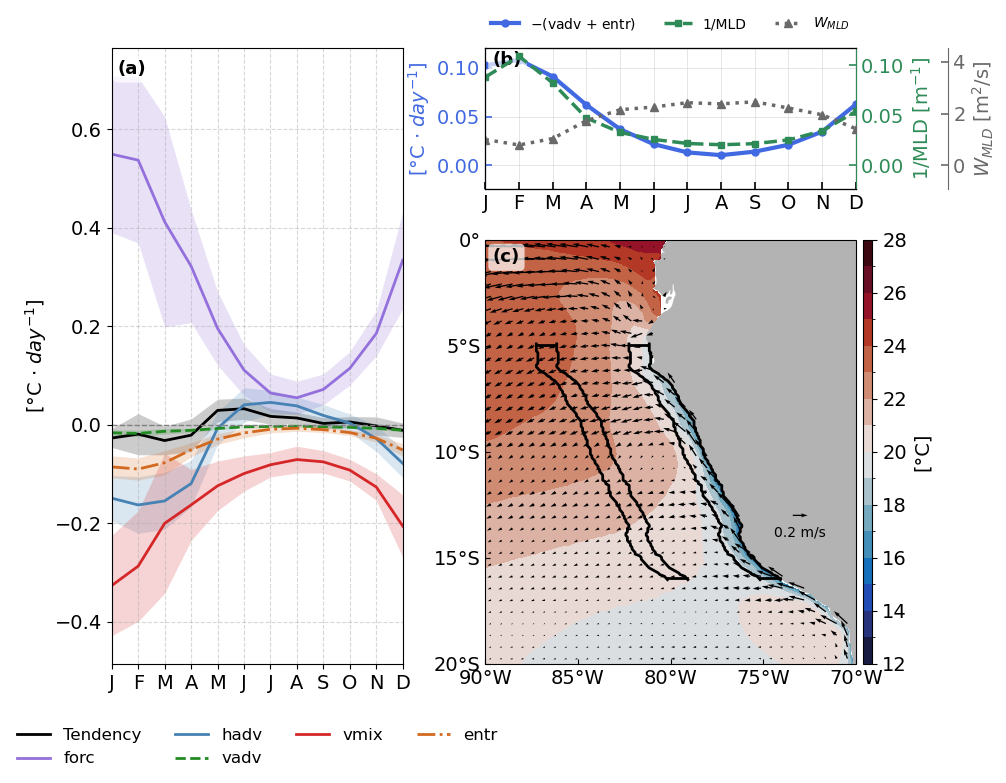

In [7]:
TICK = 14

plt.rcParams.update({
    'font.size':        12,
    'axes.titlesize':   13,
    'axes.labelsize':   TICK,
    'xtick.labelsize':  TICK,
    'ytick.labelsize':  TICK,
    'legend.fontsize':  12,
})

term_colors = {
    'rate':  'black',   'forc':  'mediumpurple', 'hadv': 'steelblue',
    'vadv': 'forestgreen',  'vmix': 'tab:red',
    'entr':  'chocolate',
}
term_labels = {
    'rate':'Tendency','forc':'forc','hadv':'hadv',
    'vadv':'vadv','vmix':'vmix','entr':'entr',
}
# line styles for red-green colour-deficient readers (colours unchanged):
#   vadv (green) / vmix (red) / entr (orange) look alike -> dashed / solid / dotted
term_styles = {
    'rate': '-',  'forc': '-',
    'hadv': '-',  'vadv': '--',
    'vmix': '-',  'entr': '-.',
}

def plot_terms(ax, mean_ds, std_ds, colors, labels, styles=None):
    styles = styles or {}
    months_ = mean_ds['month'].values
    for var, color in colors.items():
        if var not in mean_ds.data_vars:
            continue
        m = mean_ds[var].values
        s = std_ds[var].values
        ax.plot(months_, m, color=color, lw=2, ls=styles.get(var, '-'),
                label=labels[var])
        ax.fill_between(months_, m - s, m + s, color=color, alpha=0.2, linewidth=0)
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_xticks(range(1, 13))
    ax.set_xlim([1, 12])
    ax.set_xticklabels(list("JFMAMJJASOND"))
    ax.grid(True, ls='--', alpha=0.5)
    ax.tick_params(axis='both', labelsize=TICK)

# --- (a) heat budget climatology, coastal − offshore [°C/day] ---
ds_clean = ds.drop_vars(['hmix', 'temp'])
ds_clean = ds_clean.assign(hadv=ds_clean.xadv + ds_clean.yadv).drop_vars(['xadv', 'yadv'])   # horizontal advection
diff_m, diff_s = monthly_clim(ds_clean.sel(region='coast') - ds_clean.sel(region='off'))
for d in (diff_m, diff_s):
    for v in d.data_vars:
        d[v] = d[v] * 86400

proj = ccrs.PlateCarree()

# =================== Combined figure ===================
fig = plt.figure(figsize=(12*0.8, 10*0.8))
gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1.1, 1.4],
    height_ratios=[1, 3],         # B:C = 1:3
    wspace=0.25, hspace=0.18,
)

# ---------- Panel A: heat budget (spans both rows) ----------
ax_A = fig.add_subplot(gs[:, 0])
plot_terms(ax_A, diff_m, diff_s, term_colors, term_labels, styles=term_styles)
ax_A.set_ylabel('[°C $\\cdot$ $day^{-1}$]')
handles, labels = ax_A.get_legend_handles_labels()
ax_A.legend(handles, labels, ncol=4,
            loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)

# ---------- Panel B: 3-axis cooling / MLD (top right) ----------
ax1 = fig.add_subplot(gs[0, 1])
ax2 = ax1.twinx()
ax3 = ax1.twinx()
ax3.spines['right'].set_position(('axes', 1.25))

c1, c2, c3 = 'royalblue', 'seagreen', 'dimgrey'

l1, = ax1.plot(months, upw_mag, color=c1, lw=3, marker='o', ms=5,
               label='$-$(vadv + entr)')
# W_MLD integrated over the 111 km (1°) coastal band: m/s -> m²/s
WMLD_m2 = WMLD_clim.data * 111e3

l2, = ax2.plot(months, 1/MLD, color=c2, lw=2.5, ls='--', marker='s', ms=5,
               label='1/MLD')
l3, = ax3.plot(months, WMLD_m2, color=c3, lw=2.5, ls=':', marker='^', ms=6,
               label='$W_{MLD}$')

ax1.set_ylabel('[°C $\\cdot$ $day^{-1}$]', color=c1, fontsize=TICK)
ax2.set_ylabel('1/MLD [m$^{-1}$]', color=c2, fontsize=TICK)
ax3.set_ylabel('$W_{MLD}$ [m$^2$/s]', color=c3, fontsize=TICK)

ax1.tick_params(axis='y', colors=c1, direction='in', size=5, width=1.2, labelsize=TICK)
ax2.tick_params(axis='y', colors=c2, direction='in', size=5, width=1.2, labelsize=TICK)
ax3.tick_params(axis='y', colors=c3, direction='in', size=5, width=1.2, labelsize=TICK)

# each axis centred on its climatological mean, spanning mean ± 1.5|mean|
ax1.set_ylim(sym_lim(np.mean(upw_mag)))
ax2.set_ylim(sym_lim(np.mean(1/MLD)))
ax3.set_ylim(sym_lim(np.mean(WMLD_m2)))

ax1.spines['left'].set_color(c1)
ax2.spines['right'].set_color(c2)
ax3.spines['right'].set_color(c3)

ax1.set_xlim(1, 12)
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(list("JFMAMJJASOND"))
ax1.tick_params(axis='x', direction='in', size=5, width=1.2, labelsize=TICK)
ax1.grid(True, color='lightgrey', lw=0.4)
ax1.set_axisbelow(True)

lines = [l1, l2, l3]
ax1.legend(lines, [l.get_label() for l in lines],
           loc='lower center', bbox_to_anchor=(0.5, 1.02),
           fontsize=10, ncols=3, frameon=False)

# ---------- Panel C: map (bottom right) ----------
ax_C = fig.add_subplot(gs[1, 1], projection=proj)
ax_C.set_aspect('auto')           # fill the cell so C's edges line up with B

cf = sst_mean.plot.contourf(
    x="lon", y="lat",
    vmin=12, vmax=28, levels=17,
    cmap=cm.cm.balance,
    transform=proj, ax=ax_C,
    add_colorbar=False,           # colorbar gets its own axes (doesn't shrink C)
)
cax = ax_C.inset_axes([1.02, 0.0, 0.025, 1.0])
cbar = fig.colorbar(cf, cax=cax, label="[°C]")
cbar.ax.tick_params(labelsize=TICK)

Q = ax_C.quiver(
    uv_mean.lon, uv_mean.lat,
    uv_mean.u.transpose("lat", "lon").values,
    uv_mean.v.transpose("lat", "lon").values,
    transform=proj, scale=5, width=0.0035, color="k",
)
ax_C.quiverkey(Q, 0.85, 0.35, 0.2, "0.2 m/s",
               labelpos='S', coordinates='axes',
               fontproperties=dict(size=10))

# --- coastal box (111 km band) ---
ax_C.plot(coast_lons + 0.05, lat_all, color='black', lw=2, label='Coast')
ax_C.plot(offshore_lons - 0.05, lat_all, color='black', lw=2, label='Offshore')
for lat0 in coastal_b["target_lat"].values:
    if not coastal_b["transect_valid"].sel(target_lat=lat0).item():
        continue
    x0 = coastal_b["transect_x0"].sel(target_lat=lat0).item()
    x1 = coastal_b["transect_x1"].sel(target_lat=lat0).item()
    ax_C.plot([x0, x1], [lat0 + 0.05, lat0 + 0.05], color='black', lw=2, zorder=5)

# --- offshore box: the 111 km band shifted 5° west ---
ax_C.plot(coast_lons - 5 + 0.05, lat_all, color='black', lw=2, label='Offshore region')
ax_C.plot(offshore_lons - 5 - 0.05, lat_all, color='black', lw=2)
for lat0 in coastal_b["target_lat"].values:
    if not coastal_b["transect_valid"].sel(target_lat=lat0).item():
        continue
    x0 = coastal_b["transect_x0"].sel(target_lat=lat0).item() - 5
    x1 = coastal_b["transect_x1"].sel(target_lat=lat0).item() - 5
    ax_C.plot([x0, x1], [lat0 + 0.05, lat0 + 0.05], color='black', lw=2, zorder=5)

ax_C.add_feature(cfeature.LAND, facecolor="0.7")
ax_C.set_xticks([-90, -85, -80, -75, -70], crs=proj)
ax_C.set_yticks([-20, -15, -10, -5, 0], crs=proj)
ax_C.xaxis.set_major_formatter(LongitudeFormatter())
ax_C.yaxis.set_major_formatter(LatitudeFormatter())
ax_C.tick_params(axis='both', direction='in', labelsize=TICK)
ax_C.set_xlabel("")
ax_C.set_ylabel("")

def panel_label(ax, text, x=0.02, y=0.98):
    ax.text(x, y, text, transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top', ha='left',
            bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='none', alpha=0.7))

panel_label(ax_A, '(a)')
panel_label(ax1,  '(b)')
panel_label(ax_C, '(c)')

# fig.savefig('figures/heat_budget_combined_paper_new_2.png', bbox_inches='tight', dpi=300)
plt.show()


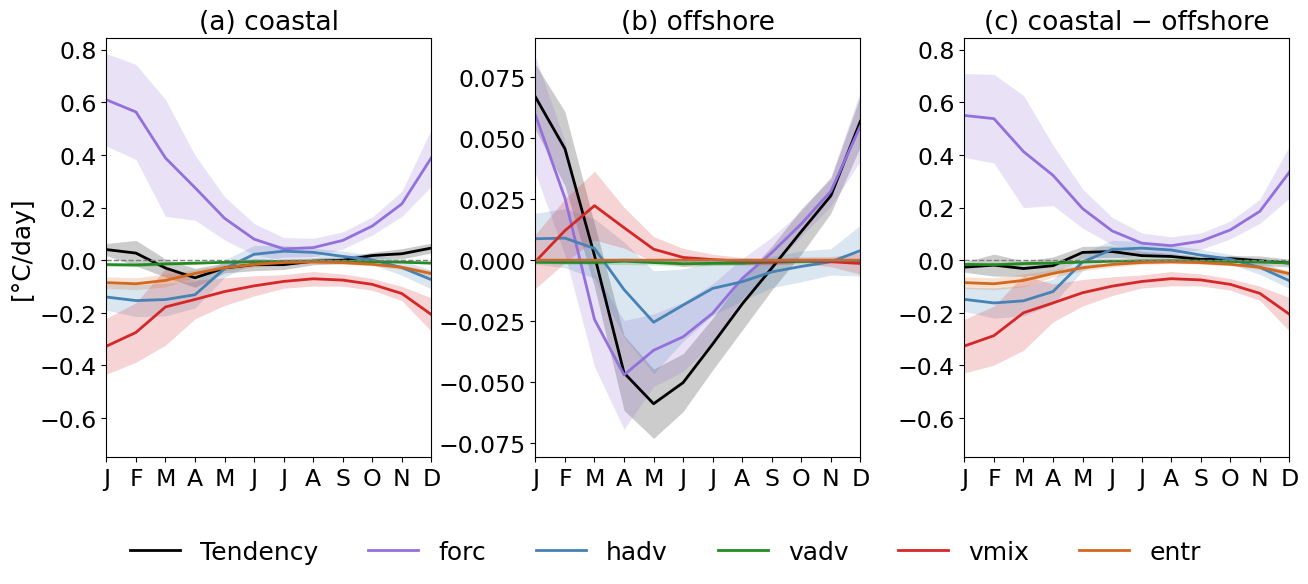

In [8]:
# ============================================================================
# Heat budget: coastal, offshore and coastal − offshore (as in SST_UV_paper.ipynb)
# ============================================================================
lsz = 6

plt.rcParams.update({
    'font.size':        12 +lsz,
    'axes.titlesize':   13+lsz,
    'axes.labelsize':   12+lsz,
    'xtick.labelsize':  11+lsz,
    'ytick.labelsize':  11+lsz,
    'legend.fontsize':  12+lsz,
})

hb_colors = {
    'rate':  'black',
    'forc':  'mediumpurple',
    'hadv':  'steelblue',
    'vadv':  'forestgreen',
    'vmix':  'tab:red',
    'entr':  'chocolate',
}

hb_labels = {
    'rate':  'Tendency',
    'forc':  'forc',
    'hadv':  'hadv',
    'vadv':  'vadv',
    'vmix':  'vmix',
    'entr':  'entr',
}

def plot_terms_titled(ax, mean_ds, std_ds, colors, labels, title):
    months_ = mean_ds['month'].values
    for var, color in colors.items():
        if var not in mean_ds.data_vars:
            continue
        m = mean_ds[var].values
        s = std_ds[var].values
        ax.plot(months_, m, color=color, lw=2, label=labels[var])
        ax.fill_between(months_, m - s, m + s, color=color, alpha=0.2, linewidth=0)
    ax.axhline(0, color='gray', ls='--', lw=1)
    ax.set_title(title)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(list("JFMAMJJASOND"))

def align_zeros(axes):
    lims = [a.get_ylim() for a in axes]
    fracs = [-ymin / (ymax - ymin) for ymin, ymax in lims]
    target = max(fracs)
    for a, (ymin, ymax) in zip(axes, lims):
        new_ymin = target * ymax / (target - 1)
        a.set_ylim(min(new_ymin, ymin), ymax)

ds_clean = ds.drop_vars(['hmix', 'temp'])
ds_clean = ds_clean.assign(hadv=ds_clean.xadv + ds_clean.yadv).drop_vars(['xadv', 'yadv'])   # horizontal advection
coast_m, coast_s = monthly_clim(ds_clean.sel(region='coast'))
off_m,   off_s   = monthly_clim(ds_clean.sel(region='off'))
dif_m,   dif_s   = monthly_clim(ds_clean.sel(region='coast') - ds_clean.sel(region='off'))

for d in (coast_m, coast_s, off_m, off_s, dif_m, dif_s):
    for v in d.data_vars:
        d[v] = d[v] * 86400

fig, ax = plt.subplots(1, 3, figsize=(13, 6))
plot_terms_titled(ax[0], coast_m, coast_s, hb_colors, hb_labels, "(a) coastal")
plot_terms_titled(ax[1], off_m,   off_s,   hb_colors, hb_labels, "(b) offshore")
plot_terms_titled(ax[2], dif_m,   dif_s,   hb_colors, hb_labels, "(c) coastal − offshore")

ax[2].sharey(ax[0])
ax[0].set_ylabel('[°C/day]')
for a in ax:
    a.set_xlim([1, 12])

align_zeros([ax[0], ax[1]])

handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, ncol=len(hb_colors),
           loc='lower center', bbox_to_anchor=(0.5, -0.015), frameon=False)

fig.subplots_adjust(wspace=0.32, left=0.07, right=0.98, top=0.9, bottom=0.2)
# fig.savefig('figures/heat_budget_seasonal_new_2.png', bbox_inches='tight', dpi=300)
plt.show()


## Heat budget with the cross-shore profile and the coastal box
As `heat_budget_combined_paper_new_2`, but (b) a little taller, (c) = heat budget terms vs distance from the coast (Appendix C, panel g) instead of the map, and (d), (e) = volume budget of the 0–20 km coastal box in summer (DJF) and winter (JJA) (Appendix C, panels i, h).
Needs `../data/croco_avg_Y1980M01.nc` (grid), `../data/Heat_budget_ML_offline.nc` and `../data/Coastal_box_volume.nc`; the figure cell also uses (a), (b) from the cells above.

In [9]:
# ============================================================================
# Data for the new figure: (c) cross-shore profile of the heat budget terms and
# (d, e) volume budget of the 0-20 km coastal box. Copied from Appendix_C (row 3),
# i.e. from Coastal_box_volume_budget; paths point to ../data/.
# ============================================================================
from matplotlib.patches import Rectangle, FancyArrow

S_DAY, SV = 86400.0, 1e6
DAYS = np.array([31, 28.25, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
SEAS = {'annual': list(range(1, 13)), 'JJA': [6, 7, 8], 'DJF': [12, 1, 2]}

# ---------------- (c) Test A cross-shore profile (REF, 5-16°S, annual mean) ----------------
# CROCO grid of the first croco_avg file: box, cell areas and distance from the coast
BOX = dict(lat=(-20.0, -2.0), lon=(-90.0, -70.0))
g = xr.open_dataset('../data/croco_avg_Y1980M01.nc')
lat_1d = g['lat_rho'].isel(xi_rho=0).values
lon_1d = g['lon_rho'].isel(eta_rho=0).values
J = np.where((lat_1d >= BOX['lat'][0]) & (lat_1d <= BOX['lat'][1]))[0]
I = np.where((lon_1d >= BOX['lon'][0]) & (lon_1d <= BOX['lon'][1]))[0]
JS, IS = slice(J[0] - 1, J[-1] + 2), slice(I[0] - 1, I[-1] + 2)
pm, pn, mask_rho = g['pm'].values[JS, IS], g['pn'].values[JS, IS], g['mask_rho'].values[JS, IS]
lat_b, lon_b = lat_1d[JS], lon_1d[IS]
g.close()
assert np.all(np.diff(lat_b) > 0), 'rows must run south -> north'
ocean = mask_rho == 1
area_b = 1 / (pm * pn)

def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.deg2rad(lat1), np.deg2rad(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.deg2rad(lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

coast_lon = np.array([lon_b[np.where(ocean[j])[0][-1]] if ocean[j].any() else np.nan for j in range(len(lat_b))])
LAT2, LON2 = np.meshgrid(lat_b, lon_b, indexing='ij')
okc = np.isfinite(coast_lon)
dist = np.full(LAT2.shape, np.nan)
for j in range(len(lat_b)):
    dist[j] = haversine_km(LAT2[j][:, None], LON2[j][:, None], lat_b[okc][None, :], coast_lon[okc][None, :]).min(axis=1)
dist[~ocean] = np.nan

def appendix_profile():
    # (Appendix_C also opened Heat_budget_ML_rotation.nc and Upwelling_pathway_maps.nc here, but used neither)
    mlx = xr.open_dataset('../data/Heat_budget_ML_offline.nc')[['T_hbl', 'forc_hbl', 'xadv_hbl', 'yadv_hbl', 'vadv_hbl',
                                                                 'vmix_hbl', 'hmix_hbl']].load()
    tt = mlx.time
    t = (tt - tt[0]).values / np.timedelta64(1, 's')
    rate = xr.DataArray(np.gradient(mlx.T_hbl.values, t, axis=mlx.T_hbl.dims.index('time')),
                        dims=mlx.T_hbl.dims, coords=mlx.T_hbl.coords)
    bud = xr.Dataset({'rate': rate, 'forc': mlx.forc_hbl, 'hadv': mlx.xadv_hbl + mlx.yadv_hbl,
                      'vadv': mlx.vadv_hbl, 'hvmix': mlx.vmix_hbl + mlx.hmix_hbl}) * S_DAY
    bud['entr'] = bud.rate - (bud.forc + bud.hadv + bud.vadv + bud.hvmix)
    bud['vcool'] = bud.vadv + bud.entr                        # − = cooling, same convention as the other terms
    bud = bud.mean('time')                                    # annual mean of all 432 months
    sl = (slice(1, -1), slice(1, -1))
    cdm = dict(dims=('lat', 'lon'), coords={'lat': mlx.lat, 'lon': mlx.lon})
    areaA, distA, oceanA = (xr.DataArray(a[sl], **cdm) for a in (area_b, dist, ocean))
    reg = (mlx.lat >= -16) & (mlx.lat <= -5)
    edges = [0, 10, 20, 30, 50, 75, 100, 150, 200]           # DIST_BINS of Test A
    rows = []
    for a, b in zip(edges[:-1], edges[1:]):
        m = oceanA & reg & (distA >= a) & (distA < b)
        w = areaA.where(m, 0.0)
        r = {k: float(bud[k].weighted(w).mean(('lat', 'lon'))) for k in ['vcool', 'hadv', 'forc', 'hvmix']}
        r.update(n=int(m.sum()), mid_km=(a + b) / 2)
        rows.append(pd.Series(r, name=f'{a}–{b}'))
    return pd.DataFrame(rows)

PA = appendix_profile()
display(PA.round(3))

# ---------------- (d, e) volume budget of box I (0-20 km, 5-16°S, alpha = 1/2) ----------------
vb = xr.open_dataset('../data/Coastal_box_volume.nc').load()
C = vb.groupby('time.month').mean('time')

def ddt_clim(x):
    # centred cyclic derivative along 'month' (per second)
    dt = np.array([(DAYS[(m - 1) % 12] / 2 + DAYS[m] + DAYS[(m + 1) % 12] / 2) for m in range(12)]) * S_DAY
    return (x.roll(month=-1, roll_coords=False) - x.roll(month=1, roll_coords=False)) / xr.DataArray(dt, dims='month', coords={'month': x.month})

def budget(c, dom, al):
    q = c.sel(domain=dom)
    qa = q.sel(alpha=al)
    dVdt, dZdt = ddt_clim(q.Sh), ddt_clim(q.Sz)
    o = xr.Dataset()
    o['base_w'], o['base_dhdt'], o['base_ugradh'], o['base_zeta'] = q.Wb, dVdt, q.UGHb, -(dZdt + q.UGZb)
    o['Q_base'] = o.base_w + o.base_dhdt + o.base_ugradh + o.base_zeta
    o['mid_w'], o['mid_dhdt'], o['mid_ugradh'], o['mid_zeta'] = qa.Wm, al * dVdt, al * qa.UGHm, -(dZdt + qa.UGZm)
    o['Q_mid'] = o.mid_w + o.mid_dhdt + o.mid_ugradh + o.mid_zeta
    for lay in ['L', 'U']:
        for f in ['off', 'N', 'S']:
            o[f'Q_{f}_{lay}'] = qa.Q.sel(layer=lay, face=f)
    o['dV_dt'], o['dVL_dt'], o['dVU_dt'] = dVdt, (1 - al) * dVdt, al * dVdt
    latL = o.Q_off_L + o.Q_N_L + o.Q_S_L
    latU = o.Q_off_U + o.Q_N_U + o.Q_S_U
    o['Q_base_res'] = dVdt + latL + latU
    o['Q_mid_res'] = al * dVdt + latU
    o['res_base'] = o.Q_base - o.Q_base_res
    o['res_mid'] = o.Q_mid - o.Q_mid_res
    o['A'] = q.A
    return o

MAIN = 'W20 5–16°S'
B0 = budget(C, MAIN, 0.5)
cq = C.sel(domain=MAIN, alpha=0.5)

def face_T(mm):
    q = cq.sel(month=mm).mean('month')
    b = B0.sel(month=mm).mean('month')
    FT, Q = q.FT, q.Q
    T = {'base (in)': float(q.WbT / q.Wb), 'mid-level': float(q.WmT / q.Wm),
         'offshore, lower half': float(FT.sel(layer='L', face='off') / Q.sel(layer='L', face='off')),
         'offshore, upper half': float(FT.sel(layer='U', face='off') / Q.sel(layer='U', face='off')),
         'box SST': float(q.SST_s / q.A)}
    V = {'base (in)': float(b.Q_base), 'mid-level': float(b.Q_mid), 'offshore, lower half': float(b.Q_off_L),
         'offshore, upper half': float(b.Q_off_U)}
    return T, V

FT_T, FT_V = {}, {}
for sname, mm in SEAS.items():
    FT_T[sname], FT_V[sname] = face_T(mm)

def season_mean(o, mm):
    return o.sel(month=mm).mean('month')

# geometry and arrow scale of Coastal_box_diagram
QMAX = max(FT_V['JJA']['base (in)'], FT_V['DJF']['base (in)']) / SV
K = 0.22 / QMAX                                  # data units of shaft width per Sv (both panels)
HW = 1.7                                         # head width / shaft width
C_UP, C_OUT, C_AL = 'k', 'tab:blue', '0.4'       # upward fluxes black, offshore blue, alongshore grey
BW, BH = 1.0, 2.0
X_ARR = 0.78
X_TIP = -0.95
BOX_20KM = dict(T=FT_T, V=FT_V, B=B0, K=K, label='20 km')
pd.DataFrame({s: {**{f'Q {k} [Sv]': v / SV for k, v in FT_V[s].items()}, **{f'T {k} [°C]': v for k, v in FT_T[s].items()}}
              for s in ['JJA', 'DJF']}).round(2)


,vcool,hadv,forc,hvmix,n,mid_km
0–10,-0.140,-0.046,0.341,-0.156,279.0,5.0
10–20,-0.040,-0.075,0.208,-0.092,156.0,15.0
20–30,-0.034,-0.068,0.179,-0.076,213.0,25.0
30–50,-0.020,-0.065,0.146,-0.061,360.0,40.0
50–75,-0.015,-0.056,0.120,-0.049,450.0,62.5
75–100,-0.013,-0.048,0.101,-0.040,440.0,87.5
100–150,-0.007,-0.044,0.081,-0.030,878.0,125.0
150–200,-0.003,-0.038,0.060,-0.019,863.0,175.0


,JJA,DJF
Q base (in) [Sv],1.99,0.95
Q mid-level [Sv],1.14,0.59
"Q offshore, lower half [Sv]",0.89,0.40
"Q offshore, upper half [Sv]",1.16,0.59
T base (in) [°C],15.72,17.79
T mid-level [°C],16.06,17.93
"T offshore, lower half [°C]",16.34,18.85
"T offshore, upper half [°C]",16.39,18.83
T box SST [°C],16.40,19.25


box font size 10 (+ BOX_DFS = 14): no label overlaps an arrow, box edge, depth tick, the coast bar or another label


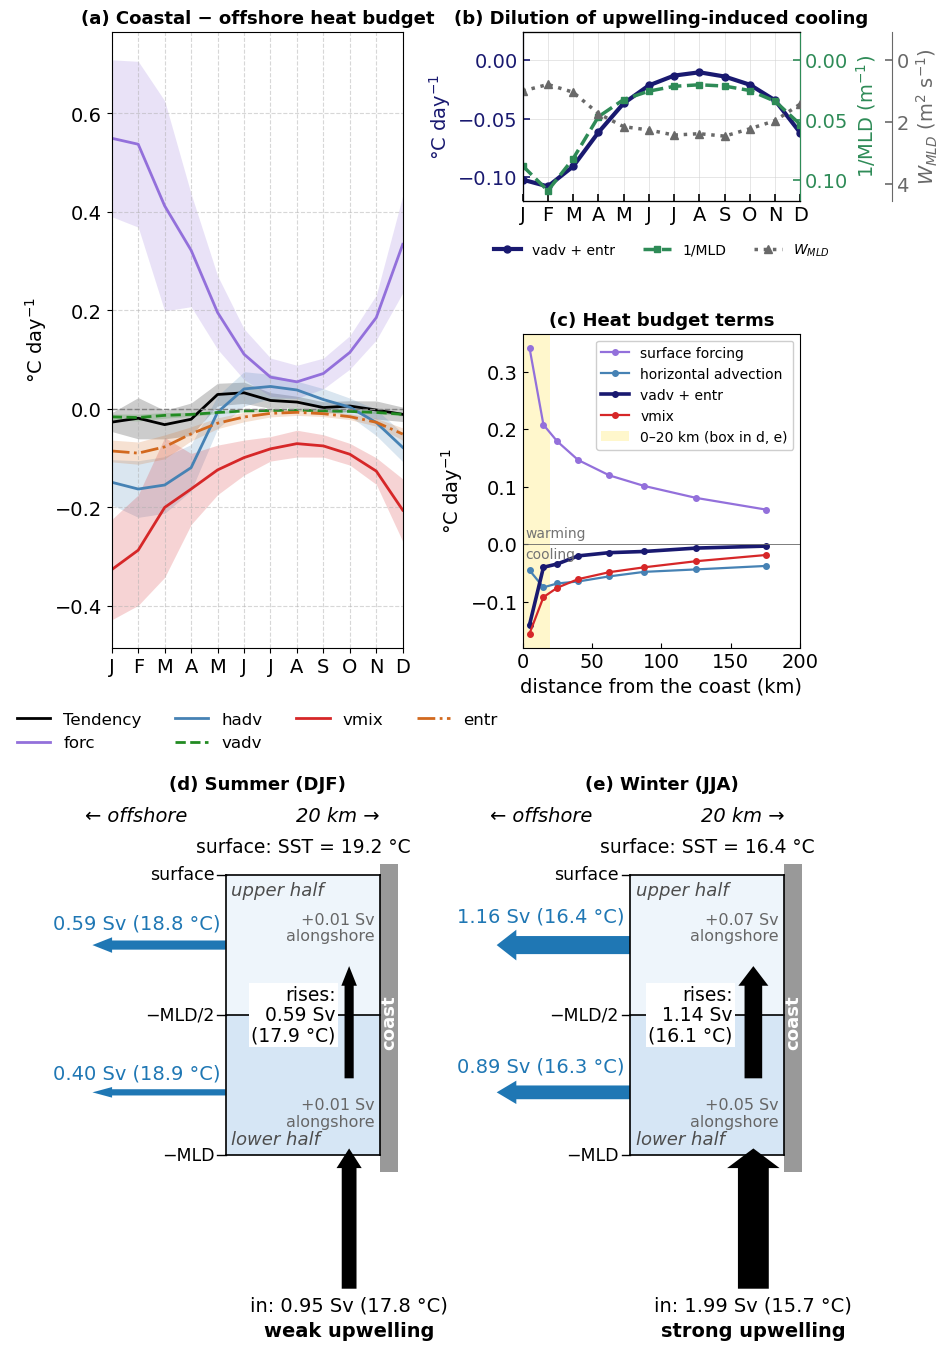

In [ ]:
# ============================================================================
# Figure: as heat_budget_combined_paper_new_2, but
#   (a) coastal − offshore heat budget (unchanged)
#   (b) cooling / 1/MLD / W_MLD, a little taller
#   (c) heat budget terms vs distance from the coast (Appendix_C (g)) instead of the map
#   (d), (e) volume budget of the 0-20 km box, summer (DJF) / winter (JJA) (Appendix_C (i), (h))
# Box panels: if a label overlaps an arrow, edge or another label, the box font shrinks (as in Appendix_C).
# ============================================================================
TICK = 14
plt.rcParams.update({                 # the cell above enlarged the fonts; back to those of the combined figure
    'font.size':        12,
    'axes.titlesize':   13,
    'axes.labelsize':   TICK,
    'xtick.labelsize':  TICK,
    'ytick.labelsize':  TICK,
    'legend.fontsize':  12,
})
LABEL_FS, TICK_FS, TITLE_FS = TICK, TICK, 13
BOX_DFS = 4                           # box panels: text = fs_box + BOX_DFS
BOX_FS  = [11, 10.5, 10, 9.5, 9, 8.5, 8, 7.5, 7]   # box label sizes tried, largest first
BOX_W   = 1.1 * BW                    # box geometry of Appendix_C
RIGHT_W = 1.05                        # width of (b), (c) relative to (a) = 1.1 (was 1.4)
B_HSPACE = 0.55                       # gap between (b) and (c) (fraction of their mean height); larger -> (b), (c) shorter
SHIFT_X = 0.05                        # (b), (c) moved right by this fraction of the figure width, so their y labels clear (a)
BOX_H   = 5.4                         # height [in] of the box row (d, e); the boxes scale with it
A_H, TOP_M = 6.16, 0.96               # height of (a) and the margin above it [in], as in the combined figure
GAP, BOT_M = 1.5, 0.9                 # [in] between (a) and the box row (legend of (a), box titles), and below
GEO     = dict(bw=BOX_W, x_arr=BOX_W - (BW - X_ARR), x_tip=X_TIP, rises_lines=3)
YLAB    = '°C day$^{-1}$'           # unit only (no variable) -> no brackets

C_VC = 'midnightblue'                 # vertical cooling, same colour in (b) and (c); not used in (a)
# hvmix = vmix + hmix, but hmix is 0 in Heat_budget_ML_offline.nc -> labelled vmix
# vcool = vadv + entr (negative = cooling, like the other terms in (c)); (b) plots the same sign
A_CURVES = [('forc', 'surface forcing', 'mediumpurple', 1.6), ('hadv', 'horizontal advection', 'steelblue', 1.6),
            ('vcool', 'vadv + entr', C_VC, 2.6), ('hvmix', 'vmix', 'tab:red', 1.6)]

def plot_profile(ax, fs):
    x = PA.mid_km.values
    for k, lab, col, lw in A_CURVES:
        ax.plot(x, PA[k], 'o-', color=col, lw=lw, ms=4, label=lab)
    ax.axhline(0, color='0.4', lw=0.6)
    ax.axvspan(0, 20, color='gold', alpha=0.2, lw=0, label='0–20 km (box in d, e)')
    ax.set_xlim(0, 200)
    ax.annotate('warming', (2, 0), xytext=(0, 2.5), textcoords='offset points', ha='left', va='bottom',
                fontsize=fs - 2, color='0.45')
    ax.annotate('cooling', (2, 0), xytext=(0, -2.5), textcoords='offset points', ha='left', va='top',
                fontsize=fs - 2, color='0.45')
    ax.set_xlabel('distance from the coast (km)', fontsize=LABEL_FS)
    ax.set_ylabel(YLAB, fontsize=LABEL_FS)
    ax.tick_params(labelsize=TICK_FS, direction='in')
    ax.legend(loc='upper right', fontsize=fs - 2, framealpha=0.95)

def panel_app(ax, s, title, fs, bw=BW, x_arr=X_ARR, x_tip=X_TIP, rises_lines=2, note='', box=None):
    # copy of panel_app() of Appendix_C
    fs = fs + BOX_DFS
    box = box or BOX_20KM
    T, V = box['T'][s], {k: v / SV for k, v in box['V'][s].items()}
    b = season_mean(box['B'], SEAS[s])
    al_in = {'L': -float(b.Q_N_L + b.Q_S_L) / SV, 'U': -float(b.Q_N_U + b.Q_S_U) / SV}   # net alongshore INTO each half
    labels, statics, obst, exempt = [], [], [], []
    ax.add_patch(Rectangle((0, 0), bw, 1, fc='#d6e6f5', ec='none'))
    ax.add_patch(Rectangle((0, 1), bw, 1, fc='#eef5fb', ec='none'))
    edges = {}
    for name, xs, ys in [('bottom', [0, bw], [0, 0]), ('mid', [0, bw], [1, 1]), ('top', [0, bw], [2, 2]),
                         ('west', [0, 0], [0, 2]), ('east', [bw, bw], [0, 2])]:
        edges[name] = ax.plot(xs, ys, color='k', lw=1.2)[0]; obst.append(edges[name])
    bar = Rectangle((bw, -0.12), 0.13, BH + 0.2, fc='0.6', ec='none'); ax.add_patch(bar); obst.append(bar)
    ax.text(bw + 0.065, 0.95, 'coast', rotation=90, ha='center', va='center', fontsize=fs - 1, color='white', fontweight='bold')
    for y, lab in [(2.0, 'surface'), (1.0, '−MLD/2'), (0.0, '−MLD')]:
        obst += ax.plot([-0.06, 0], [y, y], color='k', lw=1)
        statics.append(ax.text(-0.08, y, lab, ha='right', va='center', fontsize=fs - 1.5))
    statics.append(ax.text(0.04, 1.95, 'upper half', ha='left', va='top', fontsize=fs - 1, style='italic', color='0.3'))
    statics.append(ax.text(0.04, 0.05, 'lower half', ha='left', va='bottom', fontsize=fs - 1, style='italic', color='0.3'))
    statics.append(ax.text(x_tip - 0.05, 2.42, '← offshore', ha='left', va='center', fontsize=fs, style='italic'))
    statics.append(ax.text(bw, 2.42, f"{box['label']} →", ha='right', va='center', fontsize=fs, style='italic'))
    statics.append(ax.text(0.5 * bw, 2.13, f"surface: SST = {T['box SST']:.1f} °C", ha='center', va='bottom', fontsize=fs - 0.5))
    def arr(x, y, dx, dy, q, col):
        w = box['K'] * abs(q)
        a = FancyArrow(x, y, dx, dy, width=w, head_width=HW * w, head_length=0.14, length_includes_head=True, color=col, ec='none')
        ax.add_patch(a); obst.append(a)
        return w
    lab = lambda q, t: f"{q:.2f} Sv ({t:.1f} °C)"
    arr(x_arr, -0.95, 0, 1.0, V['base (in)'], C_UP)
    labels.append(ax.text(x_arr, -1.0, 'in: ' + lab(V['base (in)'], T['base (in)']), ha='center', va='top', fontsize=fs, color=C_UP))
    if note:                                         # e.g. 'strong upwelling', one line below the inflow label
        labels.append(ax.annotate(note, (x_arr, -1.0), xytext=(0, -1.3 * fs), textcoords='offset points',
                                  ha='center', va='top', fontsize=fs, fontweight='bold', color=C_UP))
    w = arr(x_arr, 0.55, 0, 0.8, V['mid-level'], C_UP)
    sep = '\n' if rises_lines == 3 else ' '
    tm = ax.text(x_arr - 0.5 * HW * w - 0.04, 1.0, f"rises:{sep}{V['mid-level']:.2f} Sv\n({T['mid-level']:.1f} °C)",
                 ha='right', va='center', fontsize=fs - 0.5, color=C_UP, linespacing=1.1,
                 bbox=dict(fc='white', ec='none', pad=1.5))
    labels.append(tm); exempt.append((tm, edges['mid']))
    for y, key in [(0.45, 'offshore, lower half'), (1.5, 'offshore, upper half')]:
        w = arr(0.0, y, x_tip, 0, V[key], C_OUT)
        labels.append(ax.text(-0.04, y + 0.5 * HW * w + 0.03, lab(V[key], T[key]), ha='right', va='bottom',
                              fontsize=fs, color=C_OUT))
    for y, lay in [(1.62, 'U'), (0.3, 'L')]:
        labels.append(ax.text(bw - 0.04, y, f"{al_in[lay]:+.2f} Sv\nalongshore", ha='right', va='center',
                              fontsize=fs - 2.5, color=C_AL, linespacing=1.1))
    ax.set_xlim(x_tip - 0.1, bw + 0.4); ax.set_ylim(-1.3, 2.55); ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(title, fontsize=TITLE_FS, fontweight='bold')
    return labels, statics, obst, exempt

def collisions(fig, parts):
    r = fig.canvas.get_renderer()
    hits = []
    for ax, (labels, statics, obst, exempt) in parts:
        texts = labels + statics
        for i, t in enumerate(texts):
            bt = t.get_window_extent(r).padded(1)
            for o in obst:
                if (t, o) in exempt:
                    continue
                if bt.overlaps(o.get_window_extent(r)):
                    hits.append((ax.get_title(), t.get_text().replace('\n', ' '), type(o).__name__))
            for u_ in texts[i + 1:]:
                if bt.overlaps(u_.get_window_extent(r)):
                    hits.append((ax.get_title(), t.get_text().replace('\n', ' '), 'text: ' + u_.get_text().replace('\n', ' ')))
    return hits

def draw_heat_budget_boxes(fs_box):
    # vertical layout in inches: (a) keeps the height and top margin it had in the combined figure
    # (8 in tall figure, default margins: top 0.96 in, (a) 6.16 in), the box row is added below
    H = TOP_M + A_H + GAP + BOX_H + BOT_M
    fig = plt.figure(figsize=(12*0.8, H))
    outer = fig.add_gridspec(2, 1, height_ratios=[A_H, BOX_H], hspace=GAP / ((A_H + BOX_H) / 2),
                             top=1 - TOP_M / H, bottom=BOT_M / H)
    # columns: (a) | gap | (b), (c) | free space right of (b), (c)
    # (a) and the gap are exactly as in the combined figure (width_ratios [1.1, 1.4], wspace 0.25):
    # the cells there share 1 / (1 + 0.25/2) of the width, and the gap is 0.25 x their mean width
    cells = 1 / (1 + 0.25 / 2)
    wa, wgap, wright = cells * 1.1 / 2.5, cells * 0.25 / 2, cells * 1.4 / 2.5
    wbc = wright * RIGHT_W / 1.4                       # (b), (c): narrower
    gs = outer[0].subgridspec(
        2, 4,
        width_ratios=[wa, wgap + SHIFT_X, wbc, wright - wbc - SHIFT_X],   # SHIFT_X: (b), (c) moved right, (a) unchanged
        height_ratios=[1.4, 2.6],     # (b) taller than before (was 1 : 3 with the map)
        wspace=0.0, hspace=B_HSPACE,  # room below (b) for its legend and the title of (c)
    )
    bot = outer[1].subgridspec(1, 2, wspace=0.0)

    # ---------- (a) heat budget, coastal − offshore (spans the top block) ----------
    ax_A = fig.add_subplot(gs[:, 0])
    plot_terms(ax_A, diff_m, diff_s, term_colors, term_labels, styles=term_styles)
    ax_A.set_ylabel(YLAB)
    handles, labels = ax_A.get_legend_handles_labels()
    ax_A.legend(handles, labels, ncol=4,
                loc='upper center', bbox_to_anchor=(0.5, -0.08), frameon=False)

    # ---------- (b) 3-axis cooling / MLD ----------
    ax1 = fig.add_subplot(gs[0, 2])
    ax2 = ax1.twinx()
    ax3 = ax1.twinx()
    ax3.spines['right'].set_position(('axes', 1.33))   # clear of the 1/MLD label now that (b) is narrower
    c1, c2, c3 = C_VC, 'seagreen', 'dimgrey'
    WMLD_m2 = WMLD_clim.data * 111e3              # W_MLD integrated over the 111 km coastal band: m/s -> m²/s
    vcool_b = -upw_mag                            # vadv + entr: negative = cooling, same sign as in (c)
    l1, = ax1.plot(months, vcool_b, color=c1, lw=3, marker='o', ms=5, label='vadv + entr')
    l2, = ax2.plot(months, 1/MLD, color=c2, lw=2.5, ls='--', marker='s', ms=5, label='1/MLD')
    l3, = ax3.plot(months, WMLD_m2, color=c3, lw=2.5, ls=':', marker='^', ms=6, label='$W_{MLD}$')
    ax1.set_ylabel(YLAB, color=c1, fontsize=TICK)
    ax2.set_ylabel('1/MLD (m$^{-1}$)', color=c2, fontsize=TICK)
    ax3.set_ylabel('$W_{MLD}$ (m$^{2}$ s$^{-1}$)', color=c3, fontsize=TICK)
    for a_, c_ in ((ax1, c1), (ax2, c2), (ax3, c3)):
        a_.tick_params(axis='y', colors=c_, direction='in', size=5, width=1.2, labelsize=TICK)
    ax1.set_ylim(sym_lim(np.mean(vcool_b)))
    ax2.set_ylim(sym_lim(np.mean(1/MLD)))
    ax3.set_ylim(sym_lim(np.mean(WMLD_m2)))
    # cooling is negative now: flip the 1/MLD and W_MLD axes (values unchanged, larger values lower)
    # so the three curves still run together
    ax2.invert_yaxis()
    ax3.invert_yaxis()
    ax1.spines['left'].set_color(c1)
    ax2.spines['right'].set_color(c2)
    ax3.spines['right'].set_color(c3)
    ax1.set_xlim(1, 12)
    ax1.set_xticks(range(1, 13))
    ax1.set_xticklabels(list("JFMAMJJASOND"))
    ax1.tick_params(axis='x', direction='in', size=5, width=1.2, labelsize=TICK)
    ax1.grid(True, color='lightgrey', lw=0.4)
    ax1.set_axisbelow(True)
    lines = [l1, l2, l3]
    # legend below (b), outside the axes, between (b) and the title of (c)
    leg_b = ax1.legend(lines, [l.get_label() for l in lines],
                       loc='upper center', bbox_to_anchor=(0.5, -0.17), fontsize=10, ncols=3, frameon=False)

    # ---------- (c) heat budget terms vs distance from the coast (Appendix_C (g)) ----------
    ax_C = fig.add_subplot(gs[1, 2])
    plot_profile(ax_C, 12)

    # titles in the style of (d), (e)
    ax_A.set_title('(a) Coastal − offshore heat budget', fontsize=TITLE_FS, fontweight='bold')
    ax1.set_title('(b) Dilution of upwelling-induced cooling', fontsize=TITLE_FS, fontweight='bold')
    ax_C.set_title('(c) Heat budget terms', fontsize=TITLE_FS, fontweight='bold')

    # ---------- (d), (e) volume budget of the 0-20 km box (Appendix_C (h), (i)) ----------
    ax_D, ax_E = fig.add_subplot(bot[0]), fig.add_subplot(bot[1])
    # summer first: the months of (a), (b) run J -> D, so DJF is on the left
    parts = [(ax_D, panel_app(ax_D, 'DJF', '(d) Summer (DJF)', fs_box, note='weak upwelling', **GEO)),
             (ax_E, panel_app(ax_E, 'JJA', '(e) Winter (JJA)', fs_box, note='strong upwelling', **GEO))]
    # (d) centred under (a), (e) centred under (c): shifted horizontally, size unchanged
    for ax_box, ax_ref in ((ax_D, ax_A), (ax_E, ax_C)):
        ax_box.apply_aspect()
        pr, pb = ax_ref.get_position(), ax_box.get_position()
        dx = (pr.x0 + pr.width / 2) - (pb.x0 + pb.width / 2)
        ax_box.set_position([pb.x0 + dx, pb.y0, pb.width, pb.height])
    return fig, parts, leg_b, ax_C

for fs_box in BOX_FS:
    fig, parts, leg_b, ax_C = draw_heat_budget_boxes(fs_box)
    fig.canvas.draw()
    hits = collisions(fig, parts)
    if not hits or fs_box == BOX_FS[-1]:
        break                                     # keep the last attempt open so it is displayed
    plt.close(fig)
print(f"box font size {fs_box} (+ BOX_DFS = {fs_box + BOX_DFS}): "
      + ('no label overlaps an arrow, box edge, depth tick, the coast bar or another label' if not hits
         else f'REMAINING OVERLAPS: {hits}'))
_r = fig.canvas.get_renderer()
if leg_b.get_window_extent(_r).overlaps(ax_C.title.get_window_extent(_r)):
    print('legend of (b) overlaps the title of (c): increase B_HSPACE')

# fig.savefig('Figures/heat_budget_combined_boxes.pdf', bbox_inches='tight', dpi=300)
plt.show()
